## LABS 9 - 13

## Lab 1: Bootstrap & resampling

**Q1. Bootstrap the mean of [3, 4, 5, 7, 8, 9] and report a 95% percentile interval**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(341)   # fixed seed so results are reproducible
plt.rcParams["figure.figsize"] = (7, 3.5)

Sample mean          : 6.000
Bootstrap mean       : 5.993
Bootstrap std. error : 0.877
95% percentile CI    : (4.333, 7.667)


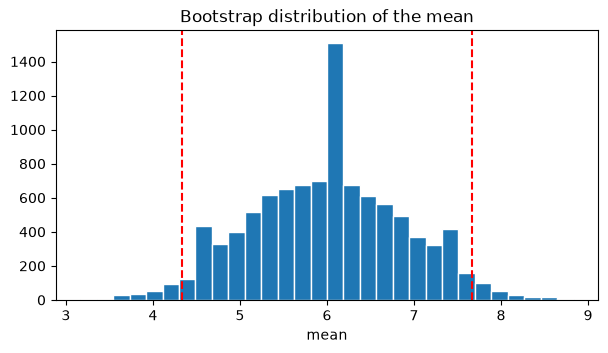

In [2]:
data = np.array([3, 4, 5, 7, 8, 9])
B = 10_000

# Resample n values with replacement, B times, and take the mean of each resample
boot_means = rng.choice(data, size=(B, data.size), replace=True).mean(axis=1)

lo, hi = np.percentile(boot_means, [2.5, 97.5])
print(f"Sample mean          : {data.mean():.3f}")
print(f"Bootstrap mean       : {boot_means.mean():.3f}")
print(f"Bootstrap std. error : {boot_means.std(ddof=1):.3f}")
print(f"95% percentile CI    : ({lo:.3f}, {hi:.3f})")

plt.hist(boot_means, bins=30, edgecolor="white")
plt.axvline(lo, color="r", ls="--"); plt.axvline(hi, color="r", ls="--")
plt.title("Bootstrap distribution of the mean"); plt.xlabel("mean"); plt.show()

The 2.5th and 97.5th percentiles of the bootstrap means give the 95% percentile interval. It is centred near the sample mean of 6, with the width reflecting how much the mean varies from sample to sample for such a small dataset.


## Q2. Bootstrap the median of the same data


Sample median        : 6.000
Bootstrap std. error : 1.385
95% percentile CI    : (3.500, 8.500)


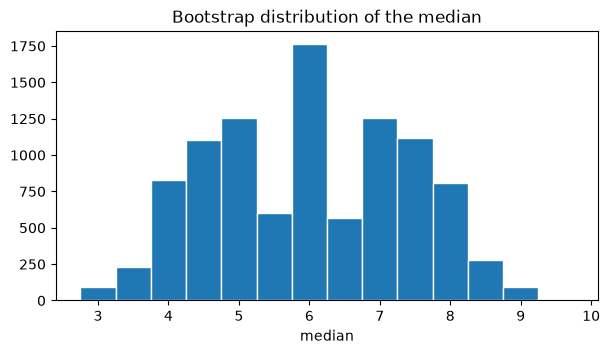

In [3]:
boot_medians = np.median(rng.choice(data, size=(B, data.size), replace=True), axis=1)
lo_m, hi_m = np.percentile(boot_medians, [2.5, 97.5])
print(f"Sample median        : {np.median(data):.3f}")
print(f"Bootstrap std. error : {boot_medians.std(ddof=1):.3f}")
print(f"95% percentile CI    : ({lo_m:.3f}, {hi_m:.3f})")

plt.hist(boot_medians, bins=np.arange(2.75, 9.8, 0.5), edgecolor="white")
plt.title("Bootstrap distribution of the median"); plt.xlabel("median"); plt.show()

The bootstrap median only takes values that are data points or midpoints of two data points, so its distribution is lumpy (discrete) rather than smooth. This is a known weakness of the bootstrap for the median with very small samples.


## Q3. Parametric bootstrap from a fitted normal model


In [4]:
# 1. Fit a normal model to the data (MLE of mean, and sample sd)
mu_hat, sigma_hat = data.mean(), data.std(ddof=1)
print(f"Fitted Normal(mu={mu_hat:.3f}, sigma={sigma_hat:.3f})")

# 2. Simulate B new datasets of the same size FROM THE FITTED MODEL (not from the data)
sim = rng.normal(mu_hat, sigma_hat, size=(B, data.size))

# 3. Compute the statistic on each simulated dataset
pb_means   = sim.mean(axis=1)
pb_medians = np.median(sim, axis=1)

for name, s in [("mean", pb_means), ("median", pb_medians)]:
    lo_, hi_ = np.percentile(s, [2.5, 97.5])
    print(f"Parametric bootstrap {name:6s}: SE = {s.std(ddof=1):.3f}, 95% CI = ({lo_:.3f}, {hi_:.3f})")

Fitted Normal(mu=6.000, sigma=2.366)
Parametric bootstrap mean  : SE = 0.969, 95% CI = (4.082, 7.844)
Parametric bootstrap median: SE = 1.098, 95% CI = (3.817, 8.124)


Unlike the non-parametric bootstrap, the parametric bootstrap resamples from the *fitted distribution*, so it can produce values not in the original data and gives a smooth distribution for the median. It is only as good as the assumed normal model.


## Q4. One way data leakage can occur during model validation


**Data leakage** happens when information from the validation/test data influences model training, making performance look better than it really is.

**Example – preprocessing before splitting.** If we standardise (or impute, or select features from) the *whole* dataset and only then split into train and test sets, the mean and standard deviation used for scaling already contain information about the test rows. The model is then evaluated on data that was not truly unseen.

**Fix:** split first, then fit every preprocessing step on the training data only (e.g. using a scikit-learn `Pipeline`, which also does this correctly inside cross-validation), and just *apply* the fitted transform to the test data.

In [5]:
# Demonstration: feature selection on the full data leaks label information
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

X = rng.normal(size=(60, 500)); y = rng.integers(0, 2, 60)   # pure noise: true accuracy is ~50%

# WRONG: select the 10 'best' features using ALL labels, then cross-validate
X_sel = SelectKBest(f_classif, k=10).fit_transform(X, y)
leaky = cross_val_score(LogisticRegression(), X_sel, y, cv=5).mean()

# RIGHT: selection happens inside each training fold
pipe = make_pipeline(SelectKBest(f_classif, k=10), LogisticRegression())
honest = cross_val_score(pipe, X, y, cv=5).mean()

print(f"Leaky CV accuracy  : {leaky:.2f}   (looks good on pure noise!)")
print(f"Honest CV accuracy : {honest:.2f}   (about chance, as it should be)")

Leaky CV accuracy  : 0.77   (looks good on pure noise!)
Honest CV accuracy : 0.52   (about chance, as it should be)


# Lab 2: Bayesian MCMC


## Q1. Random-walk Metropolis–Hastings for a standard normal target


Acceptance rate : 0.44
Mean (target 0) : 0.008
SD   (target 1) : 0.995


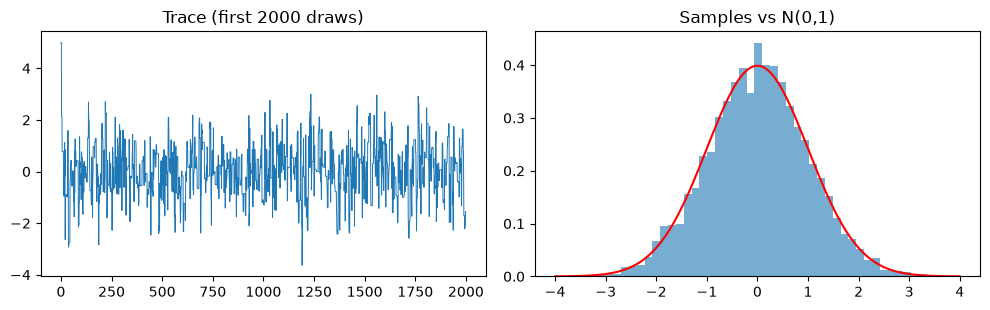

In [6]:
def rw_metropolis(log_target, x0, n_samples, step, rng):
    x = x0
    lp = log_target(x)
    samples = np.empty(n_samples)
    accepted = 0
    for i in range(n_samples):
        prop = x + step * rng.normal()            # symmetric random-walk proposal
        lp_prop = log_target(prop)
        if np.log(rng.uniform()) < lp_prop - lp:  # accept with prob min(1, ratio)
            x, lp = prop, lp_prop
            accepted += 1
        samples[i] = x
    return samples, accepted / n_samples

log_std_normal = lambda x: -0.5 * x**2            # log density up to a constant

chain, acc = rw_metropolis(log_std_normal, x0=5.0, n_samples=20_000, step=2.4, rng=rng)
post = chain[2_000:]                              # discard burn-in

print(f"Acceptance rate : {acc:.2f}")
print(f"Mean (target 0) : {post.mean():.3f}")
print(f"SD   (target 1) : {post.std():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(chain[:2000], lw=0.7); ax[0].set_title("Trace (first 2000 draws)")
ax[1].hist(post, bins=50, density=True, alpha=0.6)
xs = np.linspace(-4, 4, 200); ax[1].plot(xs, stats.norm.pdf(xs), "r"); ax[1].set_title("Samples vs N(0,1)")
plt.tight_layout(); plt.show()

## Q2. Bernoulli probability with a Beta(2,2) prior after 8 successes in 12 trials


Prior: θ ~ Beta(2, 2). Data: 8 successes, 4 failures. By conjugacy the posterior is
**Beta(2 + 8, 2 + 4) = Beta(10, 6)**, with posterior mean 10/16 = 0.625.
We estimate it with MCMC and check against this exact answer.

Acceptance rate     : 0.56
MCMC posterior mean : 0.6237   exact: 0.6250
MCMC 95% interval   : [0.371 0.838]   exact: 0.384, 0.837


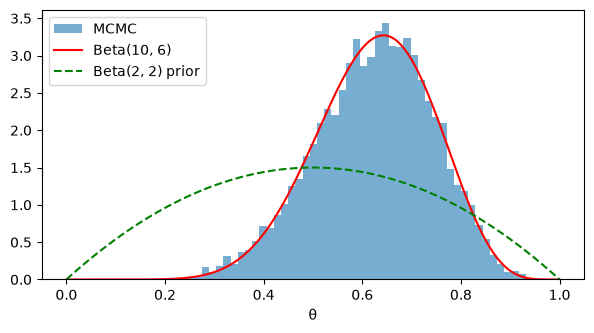

In [7]:
a0, b0, k, n = 2, 2, 8, 12

def log_post(theta):
    if theta <= 0 or theta >= 1:
        return -np.inf
    return stats.beta.logpdf(theta, a0, b0) + k*np.log(theta) + (n-k)*np.log(1-theta)

chain_b, acc_b = rw_metropolis(log_post, x0=0.5, n_samples=20_000, step=0.2, rng=rng)
theta = chain_b[2_000:]

exact = stats.beta(a0 + k, b0 + n - k)
print(f"Acceptance rate     : {acc_b:.2f}")
print(f"MCMC posterior mean : {theta.mean():.4f}   exact: {exact.mean():.4f}")
print(f"MCMC 95% interval   : {np.percentile(theta,[2.5,97.5]).round(3)}   exact: {exact.interval(0.95)[0]:.3f}, {exact.interval(0.95)[1]:.3f}")

plt.hist(theta, bins=50, density=True, alpha=0.6, label="MCMC")
xs = np.linspace(0, 1, 300); plt.plot(xs, exact.pdf(xs), "r", label="Beta(10, 6)")
plt.plot(xs, stats.beta.pdf(xs, a0, b0), "g--", label="Beta(2, 2) prior")
plt.legend(); plt.xlabel("θ"); plt.show()

## Q3. Trace plots, ACF, R-hat and ESS


| Diagnostic | What it is | What you want to see |
|---|---|---|
| **Trace plot** | The sampled value of a parameter plotted against iteration number. | A "fuzzy caterpillar": stationary around a constant level, no trends or long flat stretches, and (for several chains) all chains overlapping. |
| **ACF** (autocorrelation function) | Correlation between the chain and itself shifted by lag *k*. | ACF that drops to ~0 quickly. High autocorrelation means successive draws carry little new information. |
| **R-hat** (Gelman–Rubin) | Compares between-chain variance with within-chain variance for several chains started from different points. | Values very close to 1 (commonly < 1.01). Larger values mean the chains have not converged to the same distribution. |
| **ESS** (effective sample size) | The number of *independent* draws that would give the same precision as the autocorrelated chain: roughly N / (1 + 2Σρₖ). | ESS large relative to the number of draws (a few hundred or more per parameter, for both bulk and tail). |

R-hat = 1.0006
ESS   = 1033 of 5000 draws (chain 1)


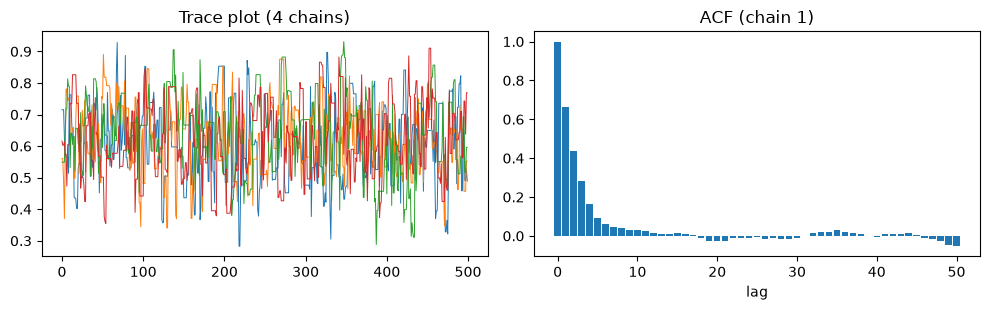

In [8]:
def acf(x, nlags=50):
    x = x - x.mean()
    full = np.correlate(x, x, mode="full")[x.size - 1:]
    return (full / full[0])[:nlags + 1]

def ess(x, max_lag=200):
    rho = acf(x, max_lag)[1:]
    cut = np.argmax(rho < 0) if np.any(rho < 0) else rho.size   # stop at first negative autocorrelation
    return x.size / (1 + 2 * rho[:cut].sum())

def rhat(chains):
    chains = np.asarray(chains); m, n = chains.shape
    W = chains.var(axis=1, ddof=1).mean()
    B_ = n * chains.mean(axis=1).var(ddof=1)
    var_hat = (n - 1) / n * W + B_ / n
    return np.sqrt(var_hat / W)

# Four chains from dispersed starting points, theta | data (Q2)
chains = [rw_metropolis(log_post, x0=s, n_samples=6000, step=0.2, rng=rng)[0][1000:] for s in (0.1, 0.4, 0.7, 0.95)]
print(f"R-hat = {rhat(chains):.4f}")
print(f"ESS   = {ess(chains[0]):.0f} of {chains[0].size} draws (chain 1)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for c in chains: ax[0].plot(c[:500], lw=0.7)
ax[0].set_title("Trace plot (4 chains)")
ax[1].bar(range(51), acf(chains[0], 50)); ax[1].set_title("ACF (chain 1)"); ax[1].set_xlabel("lag")
plt.tight_layout(); plt.show()

## Q4. PyMC model for normally distributed observations


In [9]:
try:
    import pymc as pm
    import arviz as az

    y_obs = rng.normal(loc=5.0, scale=2.0, size=100)       # simulated data: true mu=5, sigma=2

    with pm.Model() as normal_model:
        mu    = pm.Normal("mu", mu=0, sigma=10)             # weakly-informative prior for the mean
        sigma = pm.HalfNormal("sigma", sigma=5)             # positive prior for the sd
        y     = pm.Normal("y", mu=mu, sigma=sigma, observed=y_obs)
        idata = pm.sample(1000, tune=1000, chains=4, cores=1, random_seed=341, progressbar=False)

    print(az.summary(idata, var_names=["mu", "sigma"]))
except ImportError:
    print("PyMC is not installed in this environment. Run:  pip install pymc")

g++ not available, if using conda: `conda install gxx`
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [mu, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 7 seconds.


        mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu     4.786  0.202      4.5      5.1     4415     2678  1.00     0.003  0.0033
sigma  1.999  0.144      1.8      2.2     4019     2715  1.00    0.0023  0.0025


Likelihood: yᵢ ~ Normal(μ, σ). Priors: μ ~ Normal(0, 10²), σ ~ HalfNormal(5). The `az.summary` table reports the posterior mean, sd, HDI, ESS and R-hat for each parameter, so the diagnostics from Q3 can be checked directly.

# Lab 3: Advanced simulation


## Q1. 5,000 exponential samples by inverse transform (rate 3)


CDF: F(x) = 1 − e^(−λx). Inverting: x = −ln(1 − U)/λ, with U ~ Uniform(0,1).


Sample mean     : 0.3406   (theory 1/λ = 0.3333)
Sample variance : 0.1201   (theory 1/λ² = 0.1111)
KS test vs Exp(3): KstestResult(statistic=np.float64(0.012139943348087545), pvalue=np.float64(0.4491052796945325), statistic_location=np.float64(0.2789596205441012), statistic_sign=np.int8(-1))


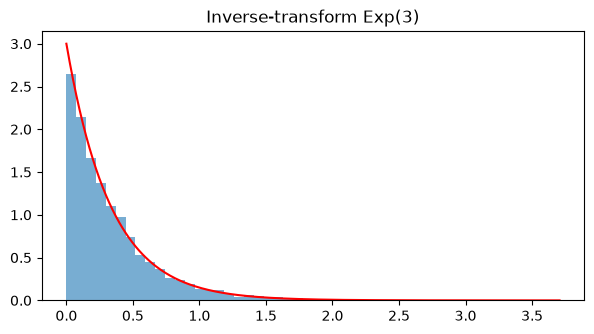

In [12]:
lam = 3
U = rng.uniform(size=5000)
x_exp = -np.log(1 - U) / lam

print(f"Sample mean     : {x_exp.mean():.4f}   (theory 1/λ = {1/lam:.4f})")
print(f"Sample variance : {x_exp.var(ddof=1):.4f}   (theory 1/λ² = {1/lam**2:.4f})")
print("KS test vs Exp(3):", stats.kstest(x_exp, "expon", args=(0, 1/lam)))

plt.hist(x_exp, bins=50, density=True, alpha=0.6)
xs = np.linspace(0, x_exp.max(), 300); plt.plot(xs, lam*np.exp(-lam*xs), "r")
plt.title("Inverse-transform Exp(3)"); plt.show()

## Q2. Sample from a categorical distribution with probabilities [0.1, 0.6, 0.3]


In [13]:
p = np.array([0.1, 0.6, 0.3])
cdf = np.cumsum(p)                                   # [0.1, 0.7, 1.0]

N = 10_000
u = rng.uniform(size=N)
cat = np.searchsorted(cdf, u, side="right")          # category = first index where cdf exceeds u

freq = np.bincount(cat, minlength=3) / N
print("Target probabilities  :", p)
print("Empirical frequencies :", freq.round(4))

Target probabilities  : [0.1 0.6 0.3]
Empirical frequencies : [0.1028 0.5926 0.3046]


The uniform draw is mapped to the interval of the cumulative distribution it falls in: [0, 0.1) → category 0, [0.1, 0.7) → category 1, [0.7, 1) → category 2.


## Q3. Rejection sampling for Beta(2,2)


Target density f(x) = 6x(1−x) on [0,1], with maximum f(0.5) = 1.5. Use a Uniform(0,1) proposal g(x) = 1 and envelope constant **M = 1.5**.
Accept x if U ≤ f(x)/(M·g(x)) = 4x(1−x). The expected acceptance rate is 1/M ≈ 0.667.

Acceptance rate  : 0.669   (theory 0.667)
Mean (theory 0.5): 0.5004
Var  (theory 0.05): 0.0505
KS test vs Beta(2,2): KstestResult(statistic=np.float64(0.008242541839229678), pvalue=np.float64(0.5026108914487746), statistic_location=np.float64(0.5111635495669087), statistic_sign=np.int8(-1))


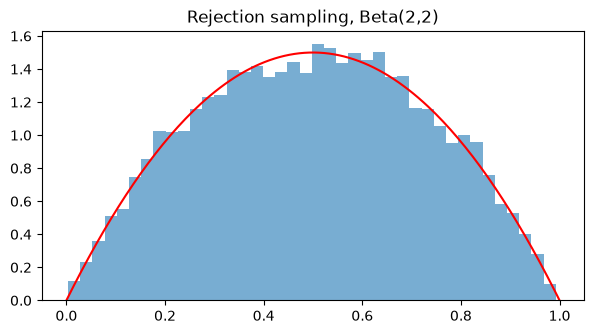

In [15]:
def rejection_beta22(n, rng):
    M = 1.5
    out, tried = [], 0
    while len(out) < n:
        x = rng.uniform(size=n)                      # proposals from Uniform(0,1)
        u = rng.uniform(size=n)
        keep = u <= stats.beta.pdf(x, 2, 2) / M      # accept if u <= f(x) / (M * g(x))
        out.extend(x[keep]); tried += n
    return np.array(out[:n]), len(out) / tried

samples, acc_rate = rejection_beta22(10_000, rng)
print(f"Acceptance rate  : {acc_rate:.3f}   (theory {1/1.5:.3f})")
print(f"Mean (theory 0.5): {samples.mean():.4f}")
print(f"Var  (theory 0.05): {samples.var(ddof=1):.4f}")
print("KS test vs Beta(2,2):", stats.kstest(samples, "beta", args=(2, 2)))

xs = np.linspace(0, 1, 200)
plt.hist(samples, bins=40, density=True, alpha=0.6); plt.plot(xs, stats.beta.pdf(xs, 2, 2), "r")
plt.title("Rejection sampling, Beta(2,2)"); plt.show()

## Q4. The four main particle-filter s

A particle filter approximates the posterior over a hidden state using a set of weighted samples ("particles"):

1. **Initialisation** – draw *N* particles from the prior distribution of the initial state, each with equal weight 1/*N*.
2. **Prediction (propagation)** – move every particle forward in time by sampling from the state-transition model p(xₜ | xₜ₋₁).
3. **Update (weighting)** – when a new observation yₜ arrives, give each particle a weight proportional to its likelihood p(yₜ | xₜ), then normalise the weights so they sum to 1.
4. **Resampling** – draw a new set of *N* particles with replacement in proportion to the weights (and reset weights to 1/*N*). This removes particles with negligible weight and duplicates good ones, preventing weight degeneracy. It is usually triggered when the effective sample size becomes too low.

The state estimate at each time is the weighted average of the particles, and steps 2–4 repeat for every new observation.

## Q5. What a non-uniform SBC rank histogram may indicate


**Simulation-based calibration (SBC)** repeatedly draws parameters from the prior, simulates data, fits the model, and records the rank of the true parameter among the posterior draws. If the inference is correct, the ranks are **uniform**. Departures indicate a problem:

- **U-shaped (peaks at both ends):** posterior is *too narrow / overconfident* – the true value often falls in the tails. Also seen with strong autocorrelation in the sampler.
- **Hump-shaped (peak in the middle):** posterior is *too wide / underconfident*.
- **Sloped, or a spike at one end:** the posterior is *biased* – systematically too high or too low compared with the truth.
- **Spikes at the extremes:** often a sign of a bug in the model or simulator, or a sampler that is not exploring properly.

Because it can't be uniform if the generating model and fitted model differ, a non-uniform histogram means a bug, a mismatch between simulator and model, or unreliable computation.

# Lab 4: Testing, estimators, packaging


## Q1. Median function with tests for a known result and empty input


In [16]:
import numpy as np
import pytest

def median(values):
    """Return the median of a 1-D sequence of numbers. Raises ValueError for empty input."""
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        raise ValueError("median() requires at least one value")
    s = np.sort(arr)
    n = s.size
    mid = n // 2
    return float(s[mid]) if n % 2 == 1 else float((s[mid - 1] + s[mid]) / 2)

# --- tests (pytest style) ---
def test_median_known_odd():
    assert median([3, 4, 5, 7, 8, 9, 1]) == 5.0       # sorted: 1 3 4 5 7 8 9

def test_median_known_even():
    assert median([3, 4, 5, 7, 8, 9]) == 6.0          # (5 + 7) / 2

def test_median_matches_numpy():
    x = np.random.default_rng(0).normal(size=101)
    assert median(x) == pytest.approx(np.median(x))

def test_median_empty_raises():
    with pytest.raises(ValueError):
        median([])
# Run the tests defined above directly in the notebook
def run_tests(*tests):
    for t in tests:
        t()
        print(f"PASSED  {t.__name__}")

run_tests(test_median_known_odd, test_median_known_even, test_median_matches_numpy, test_median_empty_raises)

PASSED  test_median_known_odd
PASSED  test_median_known_even
PASSED  test_median_matches_numpy
PASSED  test_median_empty_raises


## Q2. Tests that a probability estimate lies in [0, 1]


In [17]:
def estimate_probability(successes, trials, a=1.0, b=1.0):
    """Posterior-mean estimate of a Bernoulli probability under a Beta(a, b) prior."""
    if trials < 0 or successes < 0 or successes > trials:
        raise ValueError("need 0 <= successes <= trials")
    return (successes + a) / (trials + a + b)

def test_probability_in_unit_interval_edge_cases():
    for k, n in [(0, 0), (0, 10), (10, 10), (5, 10), (1, 1_000_000)]:
        p = estimate_probability(k, n)
        assert 0.0 <= p <= 1.0

def test_probability_in_unit_interval_random():
    rng = np.random.default_rng(1)
    for _ in range(1000):
        n = int(rng.integers(0, 500)); k = int(rng.integers(0, n + 1))
        assert 0.0 <= estimate_probability(k, n) <= 1.0

def test_probability_known_value():
    assert estimate_probability(8, 12, a=2, b=2) == pytest.approx(10 / 16)   # matches Lab 2, Q2

def test_probability_invalid_input_raises():
    with pytest.raises(ValueError):
        estimate_probability(5, 3)

run_tests(test_probability_in_unit_interval_edge_cases, test_probability_in_unit_interval_random,
          test_probability_known_value, test_probability_invalid_input_raises)

PASSED  test_probability_in_unit_interval_edge_cases
PASSED  test_probability_in_unit_interval_random
PASSED  test_probability_known_value
PASSED  test_probability_invalid_input_raises


## Q3. Transformer that scales each column by its standard deviation


In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StdScaler(BaseEstimator, TransformerMixin):
    """Divide each column by its standard deviation (no centring)."""

    def fit(self, X, y=None):
        X = check_array(X)
        self.scale_ = X.std(axis=0, ddof=0)
        self.scale_[self.scale_ == 0] = 1.0          # avoid division by zero for constant columns
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self, "scale_")
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("X has a different number of columns than during fit")
        return X / self.scale_

X = np.array([[1., 10., 5.], [2., 20., 5.], [3., 30., 5.], [4., 40., 5.]])
Xt = StdScaler().fit_transform(X)
print("Column std after scaling:", Xt.std(axis=0).round(3))   # 1, 1 and 0 (the constant column is left unchanged)

def test_unit_std():
    Z = StdScaler().fit_transform(np.random.default_rng(2).normal(3, 7, size=(200, 4)))
    assert np.allclose(Z.std(axis=0), 1.0)

def test_uses_training_scale():
    s = StdScaler().fit(X)
    assert np.allclose(s.transform(X * 2), 2 * s.transform(X))

run_tests(test_unit_std, test_uses_training_scale)

Column std after scaling: [1. 1. 0.]
PASSED  test_unit_std
PASSED  test_uses_training_scale


It follows the scikit-learn estimator API: `fit` learns the column standard deviations from the training data (stored in `scale_`, trailing underscore = learned attribute), and `transform` applies them, so it also works inside a `Pipeline` and avoids the leakage discussed in Lab 1, Q4.


## Q4. Minimal `pyproject.toml` and editable installation


In [19]:
pyproject = '''[build-system]
requires = ["setuptools>=64"]
build-backend = "setuptools.build_meta"

[project]
name = "icd341-labs"
version = "0.1.0"
description = "Helper functions for ICD 341 labs"
requires-python = ">=3.9"
dependencies = ["numpy", "scikit-learn"]

[project.optional-dependencies]
test = ["pytest"]

[tool.setuptools.packages.find]
where = ["src"]
'''
print(pyproject)

[build-system]
requires = ["setuptools>=64"]
build-backend = "setuptools.build_meta"

[project]
name = "icd341-labs"
version = "0.1.0"
description = "Helper functions for ICD 341 labs"
requires-python = ">=3.9"
dependencies = ["numpy", "scikit-learn"]

[project.optional-dependencies]
test = ["pytest"]

[tool.setuptools.packages.find]
where = ["src"]



Suggested layout:
```
icd341-labs/
├── pyproject.toml
├── src/icd341_labs/__init__.py     (median, estimate_probability, StdScaler)
└── tests/test_median.py
```
**Editable installation** (`pip install -e .` from the folder containing `pyproject.toml`) installs the package in "development mode". Instead of copying the code into `site-packages`, pip creates a link back to your source folder. The package is importable from anywhere (`import icd341_labs`), and **edits to the source files take effect immediately without reinstalling**. This is ideal while developing and running tests, and `pip install -e ".[test]"` also installs the optional test dependencies.

# Lab 5: Performance and scalability


## Q1. Vectorise x² + 2x + 1 for one million values


In [21]:
import time

x = rng.normal(size=1_000_000)

def poly_loop(x):
    out = np.empty_like(x)
    for i in range(x.size):
        out[i] = x[i]**2 + 2*x[i] + 1
    return out

t0 = time.perf_counter(); y_loop = poly_loop(x); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_vec  = x**2 + 2*x + 1;  t_vec  = time.perf_counter() - t0

print(f"Python loop : {t_loop:.4f} s")
print(f"Vectorised  : {t_vec:.4f} s   (~{t_loop/t_vec:.0f}x faster)")
print("Same result :", np.allclose(y_loop, y_vec), "| equals (x+1)**2:", np.allclose(y_vec, (x + 1)**2))

Python loop : 0.9913 s
Vectorised  : 0.0233 s   (~42x faster)
Same result : True | equals (x+1)**2: True


NumPy runs the whole operation in compiled C loops over contiguous memory, avoiding Python's per-element interpreter overhead. (Note that x² + 2x + 1 = (x + 1)², which gives a quick correctness check.)


## Q2. Numba function that sums the squares


In [22]:
from numba import njit

@njit
def sum_squares(a):
    total = 0.0
    for i in range(a.size):
        total += a[i] * a[i]
    return total

a = rng.normal(size=1_000_000)

t0 = time.perf_counter(); r1 = sum_squares(a); t_first = time.perf_counter() - t0   # includes JIT compilation
t0 = time.perf_counter(); r2 = sum_squares(a); t_second = time.perf_counter() - t0  # compiled code only
t0 = time.perf_counter(); r_np = np.sum(a**2);  t_np = time.perf_counter() - t0

print(f"First call (compile + run): {t_first:.4f} s")
print(f"Second call (run only)    : {t_second:.5f} s")
print(f"NumPy np.sum(a**2)        : {t_np:.5f} s")
print("Results agree:", np.isclose(r2, r_np))

First call (compile + run): 0.2848 s
Second call (run only)    : 0.00160 s
NumPy np.sum(a**2)        : 0.00547 s
Results agree: True


## Q3. Bootstrap a sample mean in parallel with joblib


In [23]:
from joblib import Parallel, delayed

sample = rng.normal(loc=10, scale=3, size=500)

def boot_chunk(data, n_boot, seed):
    r = np.random.default_rng(seed)
    idx = r.integers(0, data.size, size=(n_boot, data.size))
    return data[idx].mean(axis=1)

n_jobs, B_total = 4, 20_000
seeds = np.random.SeedSequence(341).spawn(n_jobs)            # independent random streams per worker

t0 = time.perf_counter()
parts = Parallel(n_jobs=n_jobs)(delayed(boot_chunk)(sample, B_total // n_jobs, s) for s in seeds)
t_par = time.perf_counter() - t0
boot = np.concatenate(parts)

print(f"{boot.size} bootstrap means in {t_par:.3f} s with {n_jobs} workers")
print(f"Sample mean {sample.mean():.3f} | bootstrap SE {boot.std(ddof=1):.4f} | theory SE {sample.std(ddof=1)/np.sqrt(sample.size):.4f}")
print("95% percentile CI:", np.percentile(boot, [2.5, 97.5]).round(3))

20000 bootstrap means in 2.634 s with 4 workers
Sample mean 10.176 | bootstrap SE 0.1289 | theory SE 0.1295
95% percentile CI: [ 9.924 10.426]


Each worker gets its own independent seed from `SeedSequence.spawn`, so workers do not repeat the same random numbers. For small tasks, the cost of starting workers can outweigh the gain; parallelism pays off when each task is heavy.


## Q4. Dask Array mean of a large chunked array


In [24]:
import dask.array as da

# 10,000 x 10,000 = 100 million values (~800 MB), split into 1,000 x 1,000 chunks (8 MB each)
big = da.random.default_rng(341).random((10_000, 10_000), chunks=(1_000, 1_000))
print("Chunks:", big.numblocks, "| chunk size:", big.chunksize)

mean_lazy = big.mean()          # builds a task graph; nothing has been computed yet
t0 = time.perf_counter()
result = mean_lazy.compute()    # processes chunk by chunk (in parallel), then combines the partial results
print(f"Mean = {result:.5f}  (theory 0.5)   computed in {time.perf_counter()-t0:.2f} s")

Chunks: (10, 10) | chunk size: (1000, 1000)
Mean = 0.49996  (theory 0.5)   computed in 0.59 s


Dask splits the array into chunks, builds a lazy task graph, and `.compute()` runs the per-chunk partial sums in parallel and combines them. The full array never has to sit in memory at once.


## Q5. Why benchmark timing should exclude Numba's first compilation call


Numba compiles a function **just-in-time**: the first call triggers type inference and compilation to machine code, and that compile time (often hundreds of milliseconds) is added to the run time of that call. Later calls with the same argument types reuse the cached compiled code and are much faster.

If the first call is included in a benchmark, the measured time is dominated by a **one-off compilation cost** instead of the function's real execution speed, and it will make Numba look slower than it is (as seen in Q2). So we do a **warm-up call first**, then time repeated calls (e.g. with `timeit`) and report the typical or minimum time. Compilation cost is still worth reporting separately, since it matters for short-lived scripts that call a function only once.